<a href="https://colab.research.google.com/github/fatihibnisa/my-ml-projekt/blob/main/Heart_Disease_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Yurak kasalliklari uchun

In [ ]:
import pandas as pd
import numpy as np


df = pd.read_csv('heart.csv')

In [ ]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
df.shape

(1025, 14)

In [ ]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


/tmp/ipykernel_895/2628563568.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette='Set2')


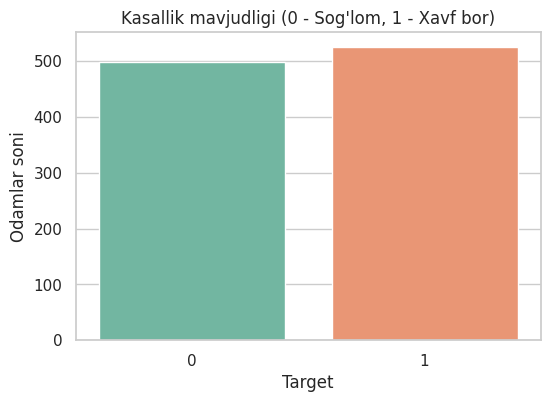

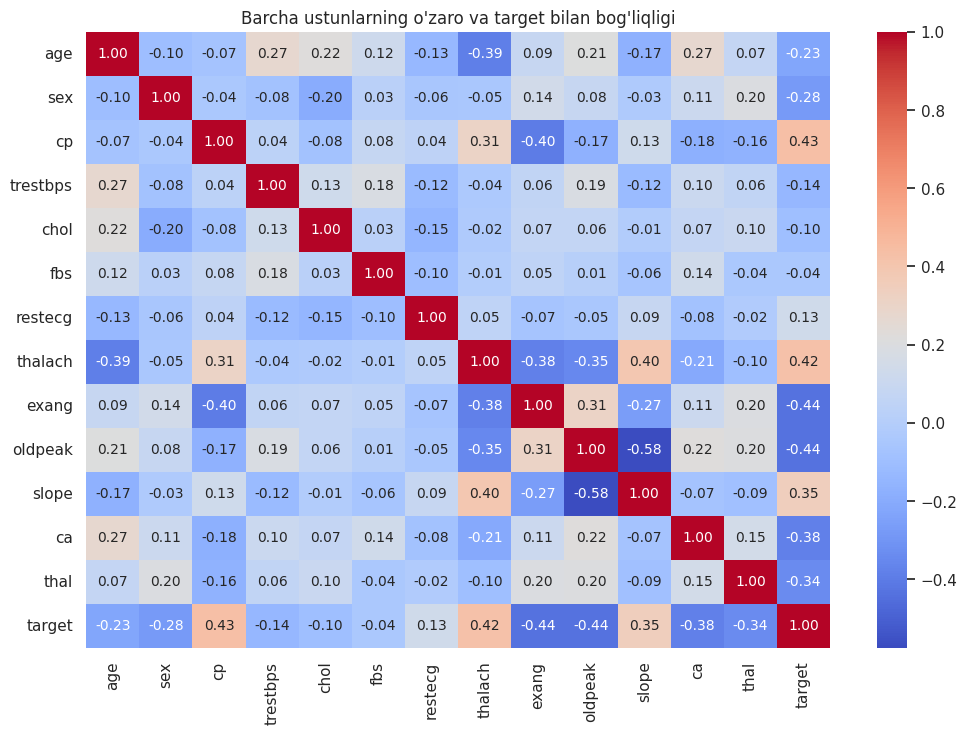

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Kasallik bor va yo'q odamlar sonini solishtirish
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df, palette='Set2')
plt.title("Kasallik mavjudligi (0 - Sog'lom, 1 - Xavf bor)")
plt.xlabel("Target")
plt.ylabel("Odamlar soni")
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Barcha ustunlarning o'zaro va target bilan bog'liqligi")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafik stilini sozlaymiz
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})

# Datani duplikatsiz toza holga keltirib olamiz
df_clean = df.drop_duplicates()

In [ ]:
df.shape

(1025, 14)

/tmp/ipykernel_895/1173171923.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='target', palette='Set2')


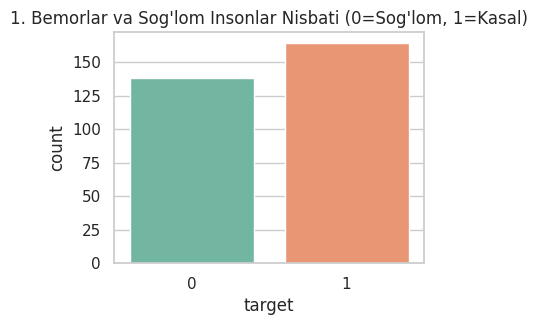

In [ ]:
plt.figure(figsize=(4, 3))
sns.countplot(data=df_clean, x='target', palette='Set2')
plt.title("1. Bemorlar va Sog'lom Insonlar Nisbati (0=Sog'lom, 1=Kasal)")
plt.show()

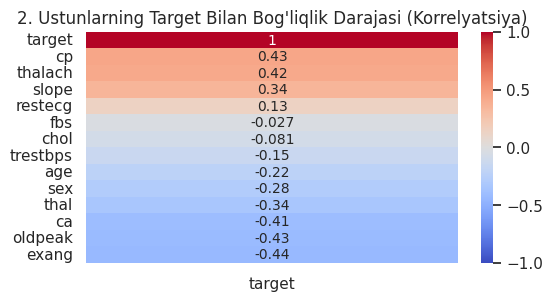

In [ ]:
plt.figure(figsize=(6, 3))
sns.heatmap(df_clean.corr()[['target']].sort_values(by='target', ascending=False),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("2. Ustunlarning Target Bilan Bog'liqlik Darajasi (Korrelyatsiya)")
plt.show()

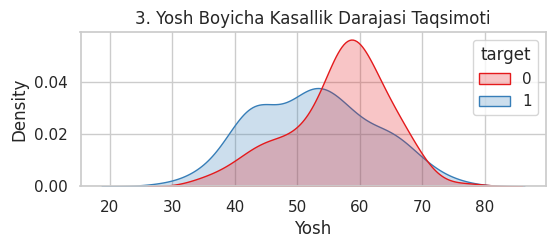

In [ ]:
plt.figure(figsize=(6, 2))
sns.kdeplot(data=df_clean, x='age', hue='target', common_norm=False, fill=True, palette='Set1')
plt.title("3. Yosh Boyicha Kasallik Darajasi Taqsimoti")
plt.xlabel("Yosh")
plt.show()

/tmp/ipykernel_895/2417377902.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='target', y='thalach', palette='Set2')


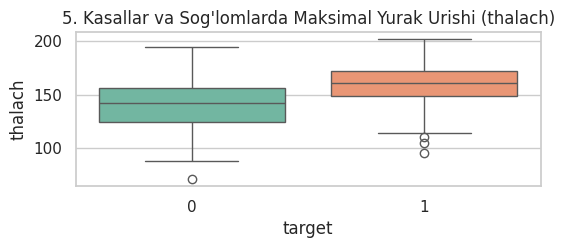

In [ ]:
plt.figure(figsize=(6, 2))
sns.boxplot(data=df_clean, x='target', y='thalach', palette='Set2')
plt.title("5. Kasallar va Sog'lomlarda Maksimal Yurak Urishi (thalach)")
plt.show()

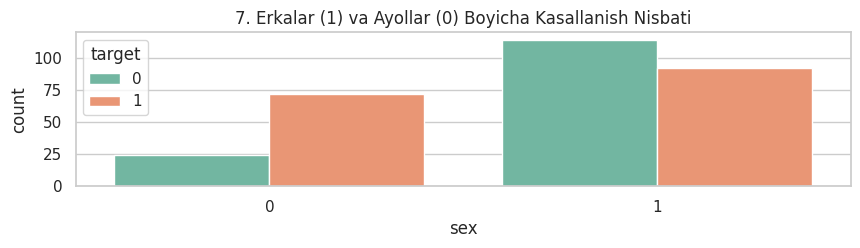

In [ ]:
plt.figure(figsize=(10, 2))
sns.countplot(data=df_clean, x='sex', hue='target', palette='Set2')
plt.title("7. Erkalar (1) va Ayollar (0) Boyicha Kasallanish Nisbati")
plt.show()

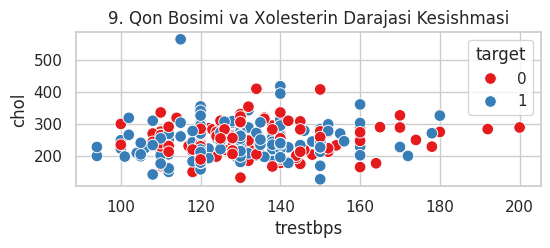

In [ ]:
plt.figure(figsize=(6, 2))
sns.scatterplot(data=df_clean, x='trestbps', y='chol', hue='target', palette='Set1', s=70)
plt.title("9. Qon Bosimi va Xolesterin Darajasi Kesishmasi")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV

In [ ]:
X = df_clean.drop('target', axis=1)
y = df_clean['target']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)

In [ ]:
xgb_model = XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42)

random forest modelini oqitamiz

In [ ]:

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)

print(f"\n--- Random Forest Natijasi ---")
print(f"Aniqlik (Accuracy): {rf_acc * 100:.2f}%")


--- Random Forest Natijasi ---
Aniqlik (Accuracy): 83.61%


xg bost modelini oqitamiz

In [ ]:

xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
xgb_acc = accuracy_score(y_test, xgb_pred)

print(f"\n--- XGBoost Natijasi ---")
print(f"Aniqlik (Accuracy): {xgb_acc * 100:.2f}%")


--- XGBoost Natijasi ---
Aniqlik (Accuracy): 78.69%


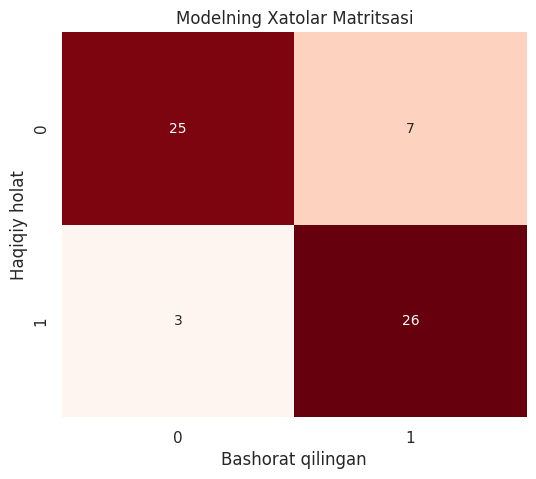

--- Batafsil Hisobot (Metrikalar) ---
              precision    recall  f1-score   support

           0       0.89      0.78      0.83        32
           1       0.79      0.90      0.84        29

    accuracy                           0.84        61
   macro avg       0.84      0.84      0.84        61
weighted avg       0.84      0.84      0.84        61



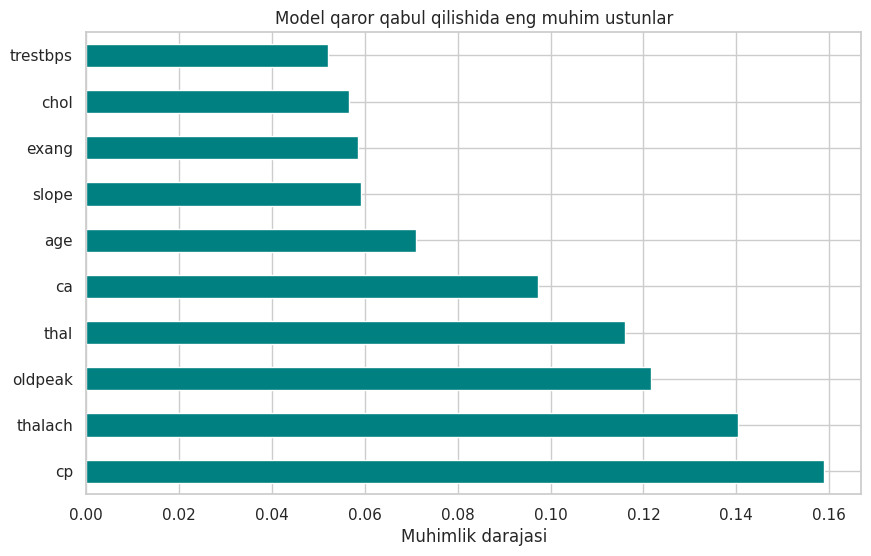

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Bashoratlarni olamiz (Random Forest yoki XGBoost)
y_pred = rf_model.predict(X_test)

# 2. Qayerda xato qilganini ko'rsatuvchi Confusion Matrix
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False)
plt.title("Modelning Xatolar Matritsasi")
plt.xlabel("Bashorat qilingan")
plt.ylabel("Haqiqiy holat")
plt.show()

# 3. Xatoliklarni chuqur tahlil qilish (Classification Report)
print("--- Batafsil Hisobot (Metrikalar) ---")
print(classification_report(y_test, y_pred))

# 4. Qaysi xususiyatlar modelni chalg'itayotganini ko'rish (Feature Importances)
feature_imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
feature_imp.head(10).plot(kind='barh', color='teal')
plt.title("Model qaror qabul qilishida eng muhim ustunlar")
plt.xlabel("Muhimlik darajasi")
plt.show()

In [96]:
import joblib

# Yurak uchun tanlangan eng yaxshi Random Forest modelini saqlaymiz
joblib.dump(rf_model, 'heart_rf_model.pkl')
print("Yurak RF modeli saqlandi!")

Yurak RF modeli saqlandi!
